# Synthetic experiments: tangent-space features of covariance matrices

Two classes of covariance matrices on the manifold $\mathbb{S}_+^h$.

**Experiment 1.** Classification accuracy versus the cloud radius $\rho$ for the projection at the Riemannian mean (TSM), the projection at $\mathbf{I}$ (log-Euclidean), the Euclidean vectorization and the MDM classifier; distance distortion against the bounds $c(\rho)$ and $g(\omega)$; invariance under channel mixing.

**Experiment 1a.** Sharpness of the constant: the distance ratio for pairs of tangent vectors with eigenvalues $\pm\rho/\sqrt2$ and rotated eigenbases tends to $c(\rho)$.

**Experiment 2.** Covariance estimation noise from $\mathcal T$ samples and the bound of the theorem.

In [1]:
import numpy as np
from scipy.linalg import eigh
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import os, json, time
%matplotlib inline
OUT = os.path.join('..', 'figs')
os.makedirs(OUT, exist_ok=True)

## Matrix functions, geodesic distance, Riemannian mean

In [2]:
def sym_fun(M, f):
    w, U = eigh(M)
    return (U * f(w)) @ U.T

def mlog(M):  return sym_fun(M, np.log)
def mexp(M):  return sym_fun(M, np.exp)
def msqrt(M): return sym_fun(M, np.sqrt)
def misqrt(M): return sym_fun(M, lambda w: 1.0 / np.sqrt(w))

def geo_dist(A, B):
    Ai = misqrt(A)
    return np.linalg.norm(mlog(Ai @ B @ Ai), "fro")

def pairwise_geo(Rs):
    """Pairwise geodesic distance matrix (batched eigvalsh)."""
    n = len(Rs); D = np.zeros((n, n))
    for i in range(n - 1):
        Ai = misqrt(Rs[i])
        w = np.linalg.eigvalsh(Ai @ Rs[i + 1:] @ Ai)
        D[i, i + 1:] = np.sqrt((np.log(w) ** 2).sum(axis=1))
    return D + D.T

def pairwise_euc(F):
    G = F @ F.T; sq = np.diag(G)
    return np.sqrt(np.maximum(sq[:, None] + sq[None, :] - 2.0 * G, 0.0))

def exp_at(R, V):          # Exp_R(V) for a tangent vector V given in whitened coordinates
    Rs = msqrt(R)
    return Rs @ mexp(V) @ Rs

def log_at(R, X):          # whitened Log_R(X) = log(R^{-1/2} X R^{-1/2})
    Ri = misqrt(R)
    return mlog(Ri @ X @ Ri)

def vec_sqrt2(S):
    h = S.shape[0]
    iu = np.triu_indices(h)
    w = np.where(iu[0] == iu[1], 1.0, np.sqrt(2.0))
    return S[iu] * w

def karcher_mean(Rs, iters=60, step=0.5, tol=1e-10):
    R = np.mean(Rs, axis=0)
    for _ in range(iters):
        Ri, Rs_ = misqrt(R), msqrt(R)
        G = np.mean([mlog(Ri @ X @ Ri) for X in Rs], axis=0)
        R = Rs_ @ mexp(step * G) @ Rs_
        if np.linalg.norm(G, "fro") < tol:
            break
    return R

def random_sym(rng, h):
    """Random symmetric matrix Z whose coordinates vec_sqrt2(Z) are independent N(0,1)."""
    G = rng.standard_normal((h, h))
    return (G + G.T) / 2.0

def g_fun(x):
    """g(x) = sinh(x/2)/(x/2), the stretch factor of the differential of the matrix exponential."""
    x = np.asarray(x, dtype=float)
    out = np.ones_like(x); m = np.abs(x) > 1e-12
    out[m] = np.sinh(x[m] / 2.0) / (x[m] / 2.0)
    return out if out.ndim else float(out)

def c_rho(rho):
    return g_fun(np.sqrt(2.0) * np.asarray(rho, dtype=float))

def spread(S):
    """omega(S) = lambda_max - lambda_min, the log condition number of exp(S)."""
    w = np.linalg.eigvalsh(S)
    return w[-1] - w[0]

## Figure style (labels typeset by LaTeX through the pgf backend)

In [3]:
def plot_style():
    """Figure labels are typeset by pdflatex through the pgf backend."""
    plt.rcParams.update({
        "pgf.texsystem": "pdflatex", "pgf.rcfonts": False,
        "pgf.preamble": "\n".join([r"\usepackage[utf8]{inputenc}", r"\usepackage[T2A]{fontenc}",
                                   r"\usepackage[russian]{babel}", r"\usepackage{amsmath,amssymb}"]),
        "font.family": "serif", "font.size": 10, "axes.labelsize": 10, "axes.titlesize": 10,
        "legend.fontsize": 8.5, "xtick.labelsize": 9, "ytick.labelsize": 9,
        "lines.linewidth": 1.2, "lines.markersize": 4, "axes.grid": True, "grid.alpha": 0.3,
        "legend.framealpha": 0.9, "legend.edgecolor": "0.8",
    })

def savefig(fig, path):
    """Save a figure through the pgf backend (LaTeX fonts)."""
    fig.savefig(path, backend="pgf", bbox_inches="tight", pad_inches=0.02)

## Generative model of the two classes

In [4]:
def sample_problem(rng, h):
    """Random reference point R0 = exp(Z0) and unit class-separation direction U."""
    R0 = exp_at(np.eye(h), random_sym(rng, h))
    U = random_sym(rng, h); U /= np.linalg.norm(U, "fro")
    return R0, U

def make_dataset(rng, h, s, n_per_class, R0, U, noise_ratio=2.0):
    """Two classes: centers Exp_{R0}(+-s/2 U), objects Exp_{center}(sigma Z), sigma = s/noise_ratio."""
    sigma = s / noise_ratio
    centers = [exp_at(R0, +0.5 * s * U), exp_at(R0, -0.5 * s * U)]
    X, y = [], []
    for c, C in enumerate(centers):
        for _ in range(n_per_class):
            E = sigma * random_sym(rng, h)
            X.append(exp_at(C, E)); y.append(c)
    return np.array(X), np.array(y)

## Features and classifiers

In [5]:
def feats_tsm(Rtr, Rte):
    Rm = karcher_mean(Rtr)
    return (np.array([vec_sqrt2(log_at(Rm, X)) for X in Rtr]),
            np.array([vec_sqrt2(log_at(Rm, X)) for X in Rte]), Rm)

def feats_logeuc(Rtr, Rte):
    return (np.array([vec_sqrt2(mlog(X)) for X in Rtr]),
            np.array([vec_sqrt2(mlog(X)) for X in Rte]))

def feats_euc(Rtr, Rte):
    return (np.array([vec_sqrt2(X) for X in Rtr]),
            np.array([vec_sqrt2(X) for X in Rte]))

def lr_acc(Ftr, ytr, Fte, yte):
    # common scalar scale of the features (no coordinatewise standardization): the regularization
    # of the logistic regression then acts identically at any scale of the cloud
    scale = np.mean(np.linalg.norm(Ftr - Ftr.mean(axis=0), axis=1))
    clf = LogisticRegression(C=1.0, max_iter=5000)
    clf.fit(Ftr / scale, ytr)
    return clf.score(Fte / scale, yte)

def mdm_acc(Rtr, ytr, Rte, yte):
    means = [karcher_mean(Rtr[ytr == c]) for c in (0, 1)]
    pred = np.array([np.argmin([geo_dist(X, M) for M in means]) for X in Rte])
    return np.mean(pred == yte)

## Experiment 1: accuracy and distance distortion versus the cloud radius

In [6]:
def experiment_radius(h=8, n_train=100, n_test=500, seeds=10,
                      s_grid=(0.1, 0.2, 0.35, 0.5, 0.75, 1.0, 1.5, 2.0, 2.5)):
    rows = []
    iu = np.triu_indices(2 * n_train, 1)
    for s in s_grid:
        acc = {k: [] for k in ("tsm", "logeuc", "euc", "mdm", "tsm_affine")}
        stat = {k: [] for k in ("rho95", "rho_max", "c_rho", "omega_max", "c_omega", "ratio_min",
                                "ratio_med", "ratio_q99", "ratio_max", "pair_frac", "affine_err")}
        for seed in range(seeds):
            rng = np.random.default_rng(seed)
            R0, U = sample_problem(rng, h)
            Rtr, ytr = make_dataset(rng, h, s, n_train, R0, U)
            Rte, yte = make_dataset(rng, h, s, n_test, R0, U)
            Ftr, Fte, Rm = feats_tsm(Rtr, Rte)
            acc["tsm"].append(lr_acc(Ftr, ytr, Fte, yte))
            d = np.array([geo_dist(Rm, X) for X in Rtr])
            stat["rho95"].append(np.quantile(d, 0.95)); stat["rho_max"].append(d.max())
            stat["c_rho"].append(c_rho(d.max()))
            # spectral spread of the tangent vectors and the refined bound g(omega)
            om = np.array([spread(log_at(Rm, X)) for X in Rtr])
            stat["omega_max"].append(om.max()); stat["c_omega"].append(g_fun(om.max()))
            # distance distortion over all pairs of training objects
            Dg = pairwise_geo(Rtr)[iu]; De = pairwise_euc(Ftr)[iu]
            ratio = Dg / De
            stat["ratio_min"].append(ratio.min()); stat["ratio_med"].append(np.median(ratio))
            stat["ratio_q99"].append(np.quantile(ratio, 0.99)); stat["ratio_max"].append(ratio.max())
            # pairwise bound g(max(omega_i, omega_j)): the ratio to it must be < 1
            stat["pair_frac"].append(np.max(ratio / g_fun(np.maximum(om[:, None], om[None, :])[iu])))
            Ftr2, Fte2 = feats_logeuc(Rtr, Rte)
            acc["logeuc"].append(lr_acc(Ftr2, ytr, Fte2, yte))
            Ftr2, Fte2 = feats_euc(Rtr, Rte)
            acc["euc"].append(lr_acc(Ftr2, ytr, Fte2, yte))
            acc["mdm"].append(mdm_acc(Rtr, ytr, Rte, yte))
            # invariance: the same after the transformation R -> A R A^T
            A = rng.standard_normal((h, h)) + 2.0 * np.eye(h)
            RtrA = np.array([A @ X @ A.T for X in Rtr]); RteA = np.array([A @ X @ A.T for X in Rte])
            FtrA, FteA, _ = feats_tsm(RtrA, RteA)
            acc["tsm_affine"].append(lr_acc(FtrA, ytr, FteA, yte))
            stat["affine_err"].append(np.max(np.abs(pairwise_euc(FtrA)[iu] - De)) / De.max())
        row = {"s": s}
        for k, v in list(stat.items()) + list(acc.items()):
            row[k] = float(np.mean(v)); row[k + "_std"] = float(np.std(v))
        rows.append(row)
        row["affine_err_max"] = float(np.max(stat["affine_err"]))
        row["pair_frac_max"] = float(np.max(stat["pair_frac"]))
        print("s=%.2f rho_max=%.2f c(rho)=%.1f omega_max=%.2f g(omega)=%.1f "
              "ratio[min/med/q99/max]=%.4f/%.3f/%.3f/%.3f pair_frac=%.3f (max %.3f)  "
              "tsm=%.3f tsm_A=%.3f logeuc=%.3f euc=%.3f mdm=%.3f  affine_err=%.1e (max %.1e)" % (
              s, row["rho_max"], row["c_rho"], row["omega_max"], row["c_omega"], row["ratio_min"],
              row["ratio_med"], row["ratio_q99"], row["ratio_max"], row["pair_frac"], row["pair_frac_max"], row["tsm"],
              row["tsm_affine"], row["logeuc"], row["euc"], row["mdm"], row["affine_err"],
              row["affine_err_max"]), flush=True)
    return rows

def plot_radius(rows, path):
    rho = np.array([r["rho_max"] for r in rows])
    xlab = r"cloud radius $\rho = \max_i \delta_{\mathcal{R}}(\bar{\mathbf{R}}, \mathbf{R}_i)$"
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(6.4, 2.9))
    for key, lab, mk in [("tsm", "TSM", "o"), ("mdm", "MDM", "s"),
                         ("logeuc", "log-Euclidean", "^"), ("euc", "Euclidean", "v")]:
        m = np.array([r[key] for r in rows]); sd = np.array([r[key + "_std"] for r in rows])
        a1.errorbar(rho, m, yerr=sd, marker=mk, capsize=2, label=lab)
    a1.set_xlabel(xlab); a1.set_ylabel("test accuracy"); a1.set_title("(a)")
    a1.set_ylim(0.45, 1.02); a1.legend(loc="lower right")
    rr = np.linspace(0.9 * rho.min(), 1.02 * rho.max(), 200)
    a2.plot(rr, c_rho(rr), "k--", label=r"bound $c(\rho)$")
    a2.plot(rho, [r["c_omega"] for r in rows], "k-.", marker="x", label=r"bound $g(\omega)$")
    for key, lab, mk in [("ratio_max", "maximum over pairs", "o"),
                         ("ratio_q99", "99th percentile", "^"),
                         ("ratio_med", "median over pairs", "s")]:
        m = np.array([r[key] for r in rows]); sd = np.array([r[key + "_std"] for r in rows])
        a2.errorbar(rho, m, yerr=sd, marker=mk, capsize=2, label=lab)
    a2.set_yscale("log"); a2.set_xlabel(xlab); a2.set_title("(b)")
    a2.set_ylabel(r"$\delta_{\mathcal{R}}(\mathbf{R}_i, \mathbf{R}_j)\,/\,\|\mathbf{p}_i - \mathbf{p}_j\|_2$")
    a2.legend(loc="upper left")
    fig.tight_layout(w_pad=1.5); savefig(fig, path); plt.show()

## Experiment 1a: sharpness of the distortion constant

In [7]:
def experiment_sharpness(h=2, rho_list=(1.0, 2.0, 4.0), thetas=np.logspace(-3, np.log10(np.pi / 2), 40)):
    """Pair S(+-theta/2) = Q D Q^T with D = diag(rho/sqrt2, -rho/sqrt2, 0, ...): the norm rho and the spread
    sqrt2*rho do not depend on theta, and delta_R/||p_i-p_j|| -> c(rho) as theta -> 0."""
    def rot(th):
        Q = np.eye(h); Q[0, 0] = Q[1, 1] = np.cos(th); Q[0, 1] = -np.sin(th); Q[1, 0] = np.sin(th)
        return Q
    out = {}
    for rho in rho_list:
        D = np.zeros((h, h)); D[0, 0] = rho / np.sqrt(2.0); D[1, 1] = -rho / np.sqrt(2.0)
        vals = []
        for th in thetas:
            Q1, Q2 = rot(-th / 2), rot(th / 2)
            S1, S2 = Q1 @ D @ Q1.T, Q2 @ D @ Q2.T
            vals.append(geo_dist(mexp(S1), mexp(S2)) / np.linalg.norm(S1 - S2, "fro"))
        out[rho] = {"theta": thetas.tolist(), "ratio": vals, "c_rho": float(c_rho(rho))}
        print("rho=%.1f c(rho)=%.4f  ratio at theta=pi/2: %.4f, at theta=1e-3: %.6f" % (
              rho, out[rho]["c_rho"], vals[-1], vals[0]), flush=True)
    return out

def plot_sharpness(out, path):
    fig, ax = plt.subplots(figsize=(3.7, 2.8))
    for k, (rho, r) in enumerate(out.items()):
        col = "C%d" % k
        ax.plot(r["theta"], r["ratio"], color=col, label=r"$\rho = %g$" % float(rho))
        ax.axhline(r["c_rho"], ls="--", lw=0.9, color=col)
    ax.set_xscale("log"); ax.set_xlabel(r"rotation angle of the eigenbasis $\theta$")
    ax.set_ylabel(r"$\delta_{\mathcal{R}}(\mathbf{R}_i, \mathbf{R}_j)\,/\,\|\mathbf{p}_i - \mathbf{p}_j\|_2$")
    hs, ls = ax.get_legend_handles_labels()
    hs.append(Line2D([0], [0], ls="--", lw=0.9, color="gray")); ls.append(r"bound $c(\rho)$")
    ax.legend(hs, ls, loc="center left")
    fig.tight_layout(); savefig(fig, path); plt.show()

## Experiment 2: covariance estimation noise

s=0.10 rho_max=0.41 c(rho)=1.0 omega_max=0.46 g(omega)=1.0 ratio[min/med/q99/max]=1.0001/1.000/1.001/1.002 pair_frac=0.998 (max 0.998)  tsm=0.816 tsm_A=0.816 logeuc=0.808 euc=0.697 mdm=0.821  affine_err=7.0e-11 (max 4.9e-10)


s=0.20 rho_max=0.82 c(rho)=1.1 omega_max=0.93 g(omega)=1.0 ratio[min/med/q99/max]=1.0003/1.002/1.004/1.007 pair_frac=0.992 (max 0.993)  tsm=0.817 tsm_A=0.817 logeuc=0.809 euc=0.697 mdm=0.823  affine_err=3.0e-11 (max 1.9e-10)


s=0.35 rho_max=1.43 c(rho)=1.2 omega_max=1.63 g(omega)=1.1 ratio[min/med/q99/max]=1.0009/1.005/1.011/1.020 pair_frac=0.976 (max 0.978)  tsm=0.819 tsm_A=0.819 logeuc=0.812 euc=0.699 mdm=0.826  affine_err=2.0e-11 (max 1.4e-10)


s=0.50 rho_max=2.05 c(rho)=1.4 omega_max=2.32 g(omega)=1.2 ratio[min/med/q99/max]=1.0017/1.009/1.022/1.039 pair_frac=0.951 (max 0.956)  tsm=0.825 tsm_A=0.825 logeuc=0.815 euc=0.703 mdm=0.831  affine_err=2.0e-11 (max 1.4e-10)


s=0.75 rho_max=3.07 c(rho)=2.0 omega_max=3.49 g(omega)=1.6 ratio[min/med/q99/max]=1.0038/1.020/1.046/1.082 pair_frac=0.894 (max 0.905)  tsm=0.837 tsm_A=0.837 logeuc=0.823 euc=0.702 mdm=0.843  affine_err=3.1e-11 (max 2.3e-10)


s=1.00 rho_max=4.10 c(rho)=3.1 omega_max=4.66 g(omega)=2.2 ratio[min/med/q99/max]=1.0063/1.033/1.076/1.133 pair_frac=0.822 (max 0.839)  tsm=0.853 tsm_A=0.853 logeuc=0.835 euc=0.706 mdm=0.858  affine_err=5.9e-11 (max 3.0e-10)


s=1.50 rho_max=6.16 c(rho)=9.0 omega_max=7.01 g(omega)=4.8 ratio[min/med/q99/max]=1.0123/1.062/1.141/1.243 pair_frac=0.654 (max 0.684)  tsm=0.887 tsm_A=0.887 logeuc=0.862 euc=0.715 mdm=0.890  affine_err=3.3e-10 (max 2.0e-09)


s=2.00 rho_max=8.23 c(rho)=29.1 omega_max=9.37 g(omega)=11.7 ratio[min/med/q99/max]=1.0182/1.092/1.206/1.359 pair_frac=0.485 (max 0.524)  tsm=0.919 tsm_A=0.919 logeuc=0.889 euc=0.721 mdm=0.922  affine_err=2.4e-09 (max 1.5e-08)


s=2.50 rho_max=10.31 c(rho)=101.6 omega_max=11.74 g(omega)=31.0 ratio[min/med/q99/max]=1.0241/1.119/1.268/1.471 pair_frac=0.340 (max 0.382)  tsm=0.948 tsm_A=0.948 logeuc=0.915 euc=0.721 mdm=0.950  affine_err=1.5e-08 (max 7.4e-08)


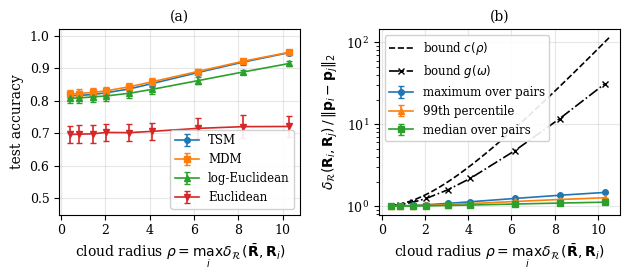

rho=1.0 c(rho)=1.0854  ratio at theta=pi/2: 1.0000, at theta=1e-3: 1.085442


rho=2.0 c(rho)=1.3683  ratio at theta=pi/2: 1.0000, at theta=1e-3: 1.368298


rho=4.0 c(rho)=2.9804  ratio at theta=pi/2: 1.0000, at theta=1e-3: 2.980371


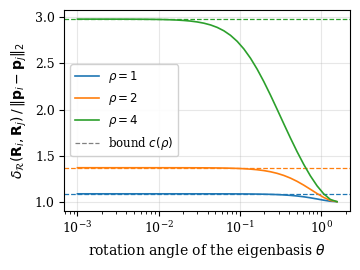

h=8 T=20  acc=0.691  err=2.302  bound=nan


h=8 T=40  acc=0.743  err=1.473  bound=40.216


h=8 T=80  acc=0.781  err=0.986  bound=9.226


h=8 T=160  acc=0.789  err=0.684  bound=4.415


h=8 T=320  acc=0.805  err=0.478  bound=2.541


...

h=16 T=160  acc=0.772  err=1.362  bound=9.056


h=16 T=320  acc=0.787  err=0.939  bound=4.809


h=16 T=640  acc=0.791  err=0.657  bound=2.891


h=16 T=1280  acc=0.797  err=0.462  bound=1.849


h=16 acc with true covariances = 0.802


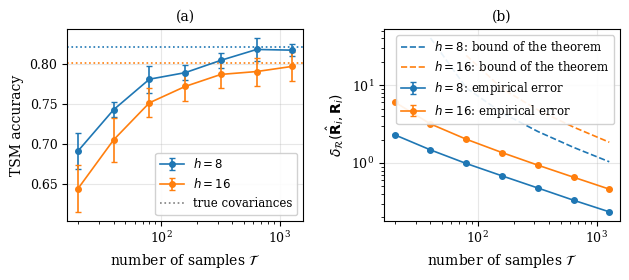

done in 227.4 s


In [8]:
def experiment_noise(h_list=(8, 16), s=0.5, n_train=100, n_test=500, seeds=10,
                     T_grid=(20, 40, 80, 160, 320, 640, 1280)):
    out, acc_true = {}, {}
    for h in h_list:
        rows = []
        for T in T_grid:
            accs, errs, bound = [], [], None
            for seed in range(seeds):
                rng = np.random.default_rng(100 + seed)
                R0, U = sample_problem(rng, h)
                Rtr, ytr = make_dataset(rng, h, s, n_train, R0, U)
                Rte, yte = make_dataset(rng, h, s, n_test, R0, U)
                def sample_cov(R):
                    Y = msqrt(R) @ rng.standard_normal((h, T))
                    return Y @ Y.T / T
                Rtr_h = np.array([sample_cov(X) for X in Rtr]); Rte_h = np.array([sample_cov(X) for X in Rte])
                Ftr, Fte, _ = feats_tsm(Rtr_h, Rte_h)
                accs.append(lr_acc(Ftr, ytr, Fte, yte))
                errs.append(np.mean([geo_dist(Xh, X) for Xh, X in zip(Rte_h[:100], Rte[:100])]))
            # bound of the theorem at confidence level 0.95
            t = np.sqrt(2.0 * np.log(2.0 / 0.05) / T); eps = np.sqrt(h / T) + t
            bound = 2 * np.sqrt(h) * eps / (1 - eps) if eps < 1 else np.nan
            rows.append({"T": T, "acc": float(np.mean(accs)), "acc_std": float(np.std(accs)),
                         "err": float(np.mean(errs)), "err_std": float(np.std(errs)), "bound": float(bound)})
            print("h=%d T=%d  acc=%.3f  err=%.3f  bound=%.3f" % (h, T, rows[-1]["acc"], rows[-1]["err"], bound), flush=True)
        out[h] = rows
        # accuracy with the true covariances on the same problems (same seeds and generation order)
        vals = []
        for seed in range(seeds):
            rng = np.random.default_rng(100 + seed)
            R0, U = sample_problem(rng, h)
            Rtr, ytr = make_dataset(rng, h, s, n_train, R0, U); Rte, yte = make_dataset(rng, h, s, n_test, R0, U)
            Ftr, Fte, _ = feats_tsm(Rtr, Rte); vals.append(lr_acc(Ftr, ytr, Fte, yte))
        acc_true[h] = float(np.mean(vals)); print("h=%d acc with true covariances = %.3f" % (h, acc_true[h]), flush=True)
    return out, acc_true

def plot_noise(out, acc_true, path):
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(6.4, 2.9))
    for k, (h, rows) in enumerate(out.items()):
        col = "C%d" % k
        T = np.array([r["T"] for r in rows])
        a1.errorbar(T, [r["acc"] for r in rows], yerr=[r["acc_std"] for r in rows], color=col,
                    marker="o", capsize=2, label=r"$h = %d$" % int(h))
        a1.axhline(acc_true[h], ls=":", color=col)
        a2.errorbar(T, [r["err"] for r in rows], yerr=[r["err_std"] for r in rows], color=col,
                    marker="o", capsize=2, label=r"$h = %d$: empirical error" % int(h))
        a2.plot(T, [r["bound"] for r in rows], "--", color=col, label=r"$h = %d$: bound of the theorem" % int(h))
    hs, ls = a1.get_legend_handles_labels()
    hs.append(Line2D([0], [0], ls=":", color="gray")); ls.append("true covariances")
    a1.set_xscale("log"); a1.set_xlabel(r"number of samples $\mathcal{T}$")
    a1.set_ylabel("TSM accuracy"); a1.set_title("(a)"); a1.legend(hs, ls, loc="lower right")
    a2.set_xscale("log"); a2.set_yscale("log"); a2.set_xlabel(r"number of samples $\mathcal{T}$"); a2.set_title("(b)")
    a2.set_ylabel(r"$\delta_{\mathcal{R}}(\hat{\mathbf{R}}_i, \mathbf{R}_i)$"); a2.legend(loc="upper right")
    fig.tight_layout(w_pad=1.5); savefig(fig, path); plt.show()
if True:
    t0 = time.time()
    plot_style()
    rows = experiment_radius()
    plot_radius(rows, os.path.join(OUT, "exp_radius.pdf"))
    sharp = experiment_sharpness()
    plot_sharpness(sharp, os.path.join(OUT, "exp_sharp.pdf"))
    out, acc_true = experiment_noise()
    plot_noise(out, acc_true, os.path.join(OUT, "exp_noise.pdf"))
    with open(os.path.join(os.getcwd(), "results.json"), "w", encoding="utf-8") as f:
        json.dump({"radius": rows, "sharpness": {str(k): v for k, v in sharp.items()},
                   "noise": {str(k): v for k, v in out.items()}, "acc_true": acc_true},
                  f, ensure_ascii=False, indent=1)
    print("done in %.1f s" % (time.time() - t0))